# Implied Vol vs. Models Through an Oil Shock

*In the 2026 oil shock, which volatility forecaster was right in each phase, the option market or the models, and can a desk switch between them in time?*

**Short answer.** The option market read the 2026 oil shock before any model did, then kept pricing danger long after the peak had passed. While a shock was building, implied volatility's one-week forecast error was two to nine times smaller than any model's. After the peak GARCH-X became the better forecaster, and selling volatility in that fading phase earned +6.3 vol points a week against +3.0 at other times.

A desk that knew the phase in advance would cut its one-week forecast error by about 12%, but no real-time rule got any of it. Four switching blends all lost to plain implied vol (0.291 at best against 0.259). The signals that should drive a switch do flag shocks early, yet they also light up on 23% to 62% of ordinary days, so every switch pays for its false alarms. Over a month implied vol wins in every phase. The main limit is the sample: almost every shock date comes from one episode.

| Question | Finding | Section |
|---|---|---|
| Does each phase have its own best forecaster? | Yes, over one week: implied vol at the onset of a shock (0.29), GARCH-X while it fades (0.32 against 0.42 for implied vol), rescaled implied vol in calm markets (0.185 against 0.200). | 6 |
| Does any real-time blend beat implied vol? | No. One week: 0.259 for implied vol, 0.291 for the best blend. One month: 0.148 against 0.307 to 0.344. | 6 |
| Do the blends beat a simple fixed-weight mix? | No. Diebold-Mariano p-values against the fixed mix range from 0.26 to 0.85. | 6 |
| Do the blends raise risk limits in time? | No. In the 2026 shock the first warning came 15 to 20 trading days after the shock began, and two blends never reacted. | 7 |
| What would perfect timing be worth? | About 12% of forecast loss over one week (0.227 against 0.259). Nothing over one month. | 8.2 |
| Do the signals see the shock coming? | Partly. Option-market signals separate shock onsets from calm days well (AUC 0.89 to 0.94), but are on for 23% to 62% of other days. | 8.3 |
| Does the fading phase help an option seller? | Possibly. Selling volatility while the shock fades earned +6.3 vol points per week against +3.0 otherwise, on 12 independent weeks from one episode. | 8.6 |

**Data.** CME WTI crude settlements and option summaries. The test runs from 2025-06-26 to 2026-05-22, 229 forecast dates. The phase labels (onset, fading, calm) look into the future, so they are used only to score forecasts and never to make one. The test period had already been studied in earlier work, so any positive result needs a fresh holdout.

**Contents**

1. Setup
2. Is the data clean, and does every forecast use only past information?
3. Which benchmarks must a blend beat?
4. How are the phases defined?
5. How are the blends built?
6. Does any blend beat implied vol?
7. Do the blends give earlier risk warnings?
8. What would perfect timing be worth, and why do the blends miss it?
9. Does the result depend on settings, and does it carry over to natural gas?
10. Conclusions

## 1 · Setup

The futures settlement price is the underlying `F`, and daily returns are log changes of the same contract, so a roll never looks like a price jump. Option summaries supply at-the-money implied vol, time to expiry and the 25-delta risk reversal. The curve feature is the front-month price minus the second month, in dollars.

HAR, the blends and the implied-vol benchmarks are fitted here. HAR-RV-IV and GARCH-X forecasts are reused from earlier work, and they were built with a slightly different implied-vol series. That difference is noted wherever it matters.

In [1]:
import os
import warnings
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = next(p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "Realized Vol",
                           Path.cwd() / "Investment Research" / "Realized Vol")
               if (p / "src" / "blends.py").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from src.data_checks import load_existing_panel
from src.features import forward_variance, build_features, evaluation_labels
from src.blends import benchmarks, fit_blends, robustness_grid
from src.evaluation import evaluate_forecasts, plot_evaluation, print_summary
from src.var_backtest import var_backtest

CONFIG = {
    "data_root": Path(os.environ.get("COMMODITY_DATA_ROOT",
        str(Path.home() / "OneDrive" / "Investment" / "Market Data" / "Commodity"))),
    "symbol": "CL", "transfer_symbols": ["NG"], "spx_panel": None,
    "horizons": (5, 20), "annualization": 252, "seed": 7,
    "calendar_name": "CMEGlobex_EnergyAndMetals", "holidays": None,
    "test_start": None, "test_fraction": 0.30,
    "ewma_warmup": 60, "minimum_train": 126, "iv_calibration_window": 504,
    "garch_window": 504, "refit": 21, "blend_minimum": 126,
    "feature_window": 252, "feature_minimum": 126,
    "jump_multiple": 3.0, "label_minimum": 126,
    "stress_quantile": .80, "onset_ratio": .70, "decay_quantile": .70,
    "hard_k_grid": [1.0, 1.5, 2.0], "hard_d_grid": [1.0],
    "hard_out_grid": [.5], "hard_exit_grid": [2, 3, 5], "hard_fall_grid": [3],
    "logistic_l2": .01, "mcs_reps": 500,
    "nu_min_train": 120, "alphas": [.01, .025],
    "output": PROJECT / "results" / "regime_blend",
    "figures": PROJECT / "figures",
}
np.random.seed(CONFIG["seed"])
CONFIG["output"].mkdir(parents=True, exist_ok=True)
CONFIG["figures"].mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)
# Show warning text without the file path of the module that raised it.
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

## 2 · Is the data clean, and does every forecast use only past information?

A forecast is only honest if it uses information available at the time it is made. This section checks the raw data before any model touches it.

Rows that fall on non-trading days are flagged using the CME energy calendar. Some holidays have an open electronic market but no settlement price, and those days are kept in the audit but left out of the forecasting calendar. No missing price is filled in. Exact-zero returns and runs of identical prices are flagged as suspicious, since they can signal stale data, but they are not removed automatically. The files only carry dates, not times of day, so the exact alignment of option and futures prices within a day cannot be checked.

Implied vol is converted to total variance using each option's time to expiry, then rescaled to a 252-day trading year. When a forecast window is shorter than the nearest expiry, that expiry's variance is held flat and the value is flagged as a proxy. For one-week forecasts this happens most of the time, so the comparison is against an approximation of true one-week implied vol.

In [2]:
audit_panel, quality_report = load_existing_panel(
    CONFIG["data_root"], PROJECT, CONFIG["symbol"], CONFIG
)
audit_panel.to_csv(CONFIG["output"] / "CL_audited_panel.csv")
quality_report.to_csv(CONFIG["output"] / "CL_data_quality.csv", index=False)
panel = audit_panel.loc[audit_panel.forecast_session.eq(True)].copy()
panel.loc[~panel.quality_valid, "ret"] = np.nan
option_dates = panel.index[panel.iv_5.notna() & panel.iv_20.notna()]
if CONFIG["test_start"] is None:
    split = int((1 - CONFIG["test_fraction"]) * len(option_dates))
    CONFIG["test_start"] = str(option_dates[split].date())
print("Test begins:", CONFIG["test_start"], "| end:", panel.index.max().date())
print("Forecast clock:", len(panel), "observed settlement sessions; no data forward filled.")
display(quality_report)
display(panel[[f"iv_{h}_proxy" for h in CONFIG["horizons"]]].loc[CONFIG["test_start"]:].mean().rename("proxy share"))

Reusing saved CL HAR-RV-IV/GARCH-X: historical IV construction differs from saved summary IV.
Data quality: 1603 rows retained; 1298 valid; 17 rows in suspicious runs (flagged, not automatically removed).
issue
exact_zero_return                   8
identical_run                       8
invalid_settlement                 40
missing_or_invalid_iv             354
missing_return                    305
non_trading_day                   272
timestamp_alignment_unverified      1
Test begins: 2025-06-26 | end: 2026-05-22
Forecast clock: 1299 observed settlement sessions; no data forward filled.


,issue,column,start,end,length,value
0,non_trading_day,,2021-03-28,2021-03-28,1,NaN
1,non_trading_day,,2021-04-04,2021-04-04,1,NaN
2,non_trading_day,,2021-04-11,2021-04-11,1,NaN
3,non_trading_day,,2021-04-18,2021-04-18,1,NaN
4,non_trading_day,,2021-04-25,2021-04-25,1,NaN
...,...,...,...,...,...,...
983,identical_run,F,2023-11-13,2023-11-14,2,78.26
984,identical_run,F,2023-11-22,2023-11-23,2,77.10
985,identical_run,F,2024-11-27,2024-11-28,2,68.72
986,identical_run,F,2025-08-07,2025-08-08,2,63.88


iv_5_proxy     0.764192
iv_20_proxy    0.065502
Name: proxy share, dtype: object

The forecasting calendar has 1,299 trading days with a settlement price. On 32 days the market was open but no front-month settlement was published, and those days are left out rather than filled in. Eight zero returns and eight rows of repeated prices are flagged for review and kept. The test period starts on 2025-06-26.

The one-week implied vol is a proxy on 76% of test dates, because the window is usually shorter than the nearest option expiry. The one-month value is a proxy on only 7%. Any one-week result that involves implied vol should be read with that in mind.

## 3 · Which benchmarks must a blend beat?

A blend is only useful if it beats the simple choices a desk already has. Five benchmarks set that bar.

EWMA is an exponentially weighted average of past squared returns, started from the variance of the first 60 returns. HAR predicts volatility from realized volatility over the last day, week and month, fitted in logs with a correction when converting back. Scaled implied vol adjusts implied vol with a rolling regression, using only past windows whose outcomes were already known. A forecast that comes out negative is reported as invalid, never clipped to zero.

The fixed-weight blend uses one weight chosen before the test starts and keeps it throughout. All new models are refitted every 21 trading days. The reused HAR-RV-IV and GARCH-X forecasts keep their original fits.

In [3]:
PREPARED = {h: benchmarks(panel, h, CONFIG) for h in CONFIG["horizons"]}
display(pd.DataFrame({h: values[0].loc[CONFIG["test_start"]:].notna().sum()
                      for h, values in PREPARED.items()}).rename_axis("benchmark"))

,5,20
benchmark,,
iv,229,229
ewma,229,229
har,228,228
har_iv,223,208
scaled_iv,229,229
garchx,224,209


Implied vol, EWMA and scaled implied vol have a forecast on all 229 test dates at both horizons, and HAR misses one. The reused HAR-RV-IV and GARCH-X forecasts cover 223 and 224 dates for one week, and 208 and 209 for one month.

## 4 · How are the phases defined?

Two kinds of quantities are built here, and they must never mix. Features are signals a trader could see at the time: the gap between implied vol and model vol, the recent change in implied vol, an inverted vol term structure, the risk reversal, recent jumps, curve moves and falling implied vol. Each is compared with its own past year of values, and nothing from the future enters.

Labels, by contrast, use the future and only grade forecasts afterwards. A date is in **stress** when the realized vol that followed was high relative to history. It is an **onset** when that stress followed a calm stretch, with trailing vol below 70% of what came next. It is **fading** (labelled decay) when vol was high but about to fall. Every other date counts as **calm**, which can include steady high-vol periods.

In [4]:
FEATURES, LABELS, TARGETS = {}, {}, {}
for h in CONFIG["horizons"]:
    FEATURES[h] = build_features(panel, np.sqrt(PREPARED[h][0].har), h, CONFIG)
    TARGETS[h] = forward_variance(panel.ret, h)
    LABELS[h] = evaluation_labels(panel.ret, h, CONFIG)
    FEATURES[h].to_csv(CONFIG["output"] / f"CL_features_h{h}.csv")
    LABELS[h].assign(target_variance=TARGETS[h]).to_csv(CONFIG["output"] / f"CL_evaluation_only_h{h}.csv")
    print("h =", h, "test label counts:")
    display(LABELS[h].loc[CONFIG["test_start"]:].sum().rename("origins"))

h = 5 test label counts:


eval_stress     62.0
eval_onset      24.0
eval_decay      49.0
eval_calm      151.0
Name: origins, dtype: float64

h = 20 test label counts:


eval_stress     56.0
eval_onset      21.0
eval_decay      32.0
eval_calm      156.0
Name: origins, dtype: float64

For one-week forecasts the test period holds 24 onset dates, 49 fading dates and 151 calm dates. For one-month forecasts the counts are 21, 32 and 156. Onset dates are few and bunched together: the 24 one-week onsets come from one or two episodes, so every onset statistic describes a single event rather than a pattern.

## 5 · How are the blends built?

Four blends mix the forecasts in different ways, each learning only from the past.

The **hard switch** jumps between forecasts when a signal crosses a threshold, and waits a few days before switching back so it does not flip back and forth. The **logistic blend** turns the signals into a smooth weight between 0 and 1, fitted to minimise forecast loss with a small penalty that keeps weights stable. The **interaction blend** is a regression that lets the effect of each forecast change with the signals. Its variance forecast includes the correction needed when converting from logs.

Every blend is trained on the forecasts its components actually made at the time, not on values refitted with hindsight. The phase labels never enter training or tuning, and any failed fit is logged rather than hidden.

In [5]:
RESULTS = {h: fit_blends(panel, h, CONFIG, prepared=PREPARED[h]) for h in CONFIG["horizons"]}
for h, result in RESULTS.items():
    result.forecasts.to_csv(CONFIG["output"] / f"CL_forecasts_h{h}.csv")
    result.weights.to_csv(CONFIG["output"] / f"CL_weights_h{h}.csv")
    result.coefficients.to_csv(CONFIG["output"] / f"CL_coefficients_h{h}.csv")
    result.diagnostics.to_csv(CONFIG["output"] / f"CL_fit_diagnostics_h{h}.csv", index=False)
    print("h =", h, "| fixed constant weight:",
          result.weights.loc[CONFIG["test_start"]:, "constant"].dropna().unique())
    display(result.forecasts.loc[CONFIG["test_start"]:].notna().sum().rename("available origins"))

h = 5 | fixed constant weight: [0.84202435]


iv             229
ewma           229
har            228
har_iv         223
scaled_iv      229
garchx         224
constant       228
hard           207
logistic       198
interaction    228
Name: available origins, dtype: int64

h = 20 | fixed constant weight: [0.69102356]


iv             229
ewma           229
har            228
har_iv         208
scaled_iv      229
garchx         209
constant       228
hard           207
logistic       198
interaction    228
Name: available origins, dtype: int64

The fixed-weight blend settles on a weight of 0.84 for one week and 0.69 for one month. The hard switch and the logistic blend have forecasts on 207 and 198 test dates, because they need more history before their first forecast. Six fitting issues are recorded in the diagnostics files.

## 6 · Does any blend beat implied vol?

All forecasts are scored on the same dates, so no model gains from easy days the others skip. The main score is QLIKE, a standard loss for variance forecasts that is zero for a perfect forecast and penalises under-prediction more than over-prediction. Diebold-Mariano tests check whether two forecasts really differ, with standard errors that allow for overlapping forecast windows. Many comparisons are made at once, so a single small p-value is a hint, not proof.

In [6]:
EVALUATIONS = {}
for h, result in RESULTS.items():
    test_forecasts = result.forecasts.loc[CONFIG["test_start"]:]
    EVALUATIONS[h] = evaluate_forecasts(
        TARGETS[h].reindex(test_forecasts.index), test_forecasts,
        LABELS[h].reindex(test_forecasts.index), h,
        seed=CONFIG["seed"], mcs_reps=CONFIG["mcs_reps"],
    )
    for name, table in EVALUATIONS[h].items():
        table.to_csv(CONFIG["output"] / f"CL_{name}_h{h}.csv")
    display(EVALUATIONS[h]["scores"])
    display(EVALUATIONS[h]["dm"])
    display(EVALUATIONS[h]["mcs"])
    plot_evaluation(TARGETS[h].reindex(test_forecasts.index), test_forecasts,
                    LABELS[h].reindex(test_forecasts.index),
                    result.weights.reindex(test_forecasts.index),
                    result.coefficients.loc[CONFIG["test_start"]:], h,
                    CONFIG["figures"] / "CL")

,model,regime,count,QLIKE,MSE
0,iv,all,193,0.258887,0.133009
1,ewma,all,193,0.505414,0.158887
2,har,all,193,0.517051,0.159793
3,har_iv,all,193,0.284466,0.113758
4,scaled_iv,all,193,0.280609,0.129439
5,garchx,all,193,0.326190,0.135213
6,constant,all,193,0.294157,0.129530
7,hard,all,193,0.313885,0.127192
8,logistic,all,193,0.291282,0.129308
9,interaction,all,193,0.308522,0.120928


,model,benchmark,count,mean_QLIKE_difference,dm,pvalue,hac_se,hac_lag,status,reason
0,har_iv,har,193,-0.232585,-1.794228,0.072777,0.129630,4,ok,
1,garchx,har,193,-0.190861,-1.881177,0.059948,0.101458,4,ok,
2,hard,har,193,-0.203166,-1.549471,0.121268,0.131120,4,ok,
3,logistic,har,193,-0.225769,-1.763101,0.077884,0.128052,4,ok,
4,interaction,har,193,-0.208529,-1.783939,0.074434,0.116892,4,ok,
5,har_iv,scaled_iv,193,0.003857,0.395373,0.692568,0.009755,4,ok,
6,garchx,scaled_iv,193,0.045581,1.440954,0.149598,0.031633,4,ok,
7,hard,scaled_iv,193,0.033276,1.715193,0.086310,0.019401,4,ok,
8,logistic,scaled_iv,193,0.010673,2.407161,0.016077,0.004434,4,ok,
9,interaction,scaled_iv,193,0.027914,1.465584,0.142762,0.019046,4,ok,


,model,status,reason,eligible_origins,lost_complete_origins,missing_or_incomplete_origins,block_size,mcs_90,pvalue,segment_start,segment_end,equivalence_group,equivalent_models,unique_loss_paths
0,iv,ok,,36,157,36,5,True,1.000,2026-03-24,2026-05-13,iv,"(iv,)",10
1,ewma,ok,,36,157,36,5,True,0.294,2026-03-24,2026-05-13,ewma,"(ewma,)",10
2,har,ok,,36,157,36,5,True,0.476,2026-03-24,2026-05-13,har,"(har,)",10
3,har_iv,ok,,36,157,36,5,True,0.726,2026-03-24,2026-05-13,har_iv,"(har_iv,)",10
4,scaled_iv,ok,,36,157,36,5,True,0.638,2026-03-24,2026-05-13,scaled_iv,"(scaled_iv,)",10
5,garchx,ok,,36,157,36,5,True,0.466,2026-03-24,2026-05-13,garchx,"(garchx,)",10
6,constant,ok,,36,157,36,5,True,0.516,2026-03-24,2026-05-13,constant,"(constant,)",10
7,hard,ok,,36,157,36,5,True,0.726,2026-03-24,2026-05-13,hard,"(hard,)",10
8,logistic,ok,,36,157,36,5,True,0.638,2026-03-24,2026-05-13,logistic,"(logistic,)",10
9,interaction,ok,,36,157,36,5,True,0.726,2026-03-24,2026-05-13,interaction,"(interaction,)",10


,model,regime,count,QLIKE,MSE
0,iv,all,180,0.147633,0.030972
1,ewma,all,180,0.428495,0.073001
2,har,all,180,0.471684,0.086738
3,har_iv,all,180,0.248752,0.055123
4,scaled_iv,all,180,0.293819,0.064134
5,garchx,all,180,0.197676,0.045351
6,constant,all,180,0.321568,0.062499
7,hard,all,180,0.326576,0.060509
8,logistic,all,180,0.307147,0.064633
9,interaction,all,180,0.343627,0.073191


,model,benchmark,count,mean_QLIKE_difference,dm,pvalue,hac_se,hac_lag,status,reason
0,har_iv,har,180,-0.222932,-1.866655,0.061950,0.119429,19,ok,
1,garchx,har,180,-0.274009,-1.890408,0.058703,0.144947,19,ok,
2,hard,har,180,-0.145108,-1.459206,0.144508,0.099443,19,ok,
3,logistic,har,180,-0.164537,-1.769029,0.076889,0.093010,19,ok,
4,interaction,har,180,-0.128057,-1.790460,0.073380,0.071522,19,ok,
5,har_iv,scaled_iv,180,-0.045068,-1.341188,0.179859,0.033603,19,ok,
6,garchx,scaled_iv,180,-0.096144,-1.617805,0.105705,0.059428,19,ok,
7,hard,scaled_iv,180,0.032757,1.377304,0.168418,0.023784,19,ok,
8,logistic,scaled_iv,180,0.013328,2.156995,0.031006,0.006179,19,ok,
9,interaction,scaled_iv,180,0.049807,1.123974,0.261024,0.044314,19,ok,


,model,status,reason,eligible_origins,lost_complete_origins,missing_or_incomplete_origins,block_size,mcs_90,pvalue,segment_start,segment_end,equivalence_group,equivalent_models,unique_loss_paths
0,iv,ok,,30,150,49,20,False,0.002,2025-06-26,2025-08-07,iv,"(iv,)",9
1,ewma,ok,,30,150,49,20,False,0.000,2025-06-26,2025-08-07,ewma,"(ewma,)",9
2,har,equivalent_loss_group,Exactly identical loss paths share one MCS rep...,30,150,49,20,False,0.000,2025-06-26,2025-08-07,har,"(har, hard)",9
3,har_iv,ok,,30,150,49,20,False,0.000,2025-06-26,2025-08-07,har_iv,"(har_iv,)",9
4,scaled_iv,ok,,30,150,49,20,True,1.000,2025-06-26,2025-08-07,scaled_iv,"(scaled_iv,)",9
5,garchx,ok,,30,150,49,20,False,0.002,2025-06-26,2025-08-07,garchx,"(garchx,)",9
6,constant,ok,,30,150,49,20,False,0.000,2025-06-26,2025-08-07,constant,"(constant,)",9
7,hard,equivalent_loss_group,Exactly identical loss paths share one MCS rep...,30,150,49,20,False,0.000,2025-06-26,2025-08-07,har,"(har, hard)",9
8,logistic,ok,,30,150,49,20,False,0.000,2025-06-26,2025-08-07,logistic,"(logistic,)",9
9,interaction,ok,,30,150,49,20,False,0.002,2025-06-26,2025-08-07,interaction,"(interaction,)",9


Over all 193 common one-week dates, implied vol has the lowest loss at 0.259. Scaled implied vol (0.281) and HAR-RV-IV (0.284) come next, then the four blends between 0.291 and 0.314. GARCH-X scores 0.326 and plain HAR 0.517.

The picture changes when the dates are split by phase. At the onset of a shock implied vol scores 0.294, while every other forecast lands between 0.66 and 2.51: the option market reacts first. While a shock fades, GARCH-X wins with 0.317 against 0.420 for implied vol, which stays too high after the peak. In calm markets scaled implied vol edges ahead, 0.185 against 0.200.

Over one month implied vol wins outright with 0.148, ahead of GARCH-X at 0.198 and the blends at 0.307 to 0.344. It also wins at onset and ties GARCH-X while the shock fades.

No blend beats the fixed-weight mix: the p-values are 0.26 to 0.60 for one week and 0.31 to 0.85 for one month. The hard switch is significantly worse than implied vol at both horizons (p = 0.03 and 0.045).

One standard test does not work here. The model confidence set needs an unbroken run of dates on which every forecast exists. For one week that run is 36 dates in spring 2026, too short to separate anything. For one month it is 30 calm dates in summer 2025, so its verdict describes one quiet summer. Section 8 replaces it with intervals that use every common date.

## 7 · Do the blends give earlier risk warnings?

A forecast can also set a risk limit. Each forecast is turned into a one-day value-at-risk at the 99% and 97.5% levels, under a normal and a fat-tailed distribution, and compared with the next day's return. Three questions follow: are limits breached as often as they should be, how quickly does the limit rise when a shock begins, and how often does the hard switch raise a false alarm? With so few shocks, the answers by phase are descriptive.

In [7]:
RISKS = {}
for h, result in RESULTS.items():
    RISKS[h] = var_backtest(panel.ret, result.forecasts, LABELS[h], h, CONFIG,
                           hard_mode=result.weights.hard)
    for name, table in RISKS[h].items():
        table.to_csv(CONFIG["output"] / f"CL_risk_{name}_h{h}.csv")
    display(RISKS[h]["breaches"])
    display(RISKS[h]["lead_times"])
    display(RISKS[h]["false_alarms"])

,model,distribution,alpha,regime,count,breaches,kupiec_p,independence_p,conditional_coverage_p,n00,n01,n10,n11,status,reason
0,iv,normal,0.010,all,228,4,0.300925,NaN,NaN,219,4,4,0,partial,degenerate breach transition probabilities
1,iv,normal,0.010,eval_stress,62,2,0.161942,NaN,NaN,51,2,2,0,partial,degenerate breach transition probabilities
2,iv,normal,0.010,eval_onset,24,2,0.023998,NaN,NaN,13,2,0,0,partial,insufficient breach transitions
3,iv,normal,0.010,eval_decay,49,0,0.320984,NaN,NaN,37,0,0,0,partial,insufficient breach transitions
4,iv,normal,0.010,eval_calm,151,2,0.702623,NaN,NaN,132,2,2,0,partial,degenerate breach transition probabilities
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,interaction,student_t,0.025,all,227,7,0.586589,NaN,NaN,211,7,7,0,partial,degenerate breach transition probabilities
196,interaction,student_t,0.025,eval_stress,62,5,0.025164,NaN,NaN,45,5,5,0,partial,degenerate breach transition probabilities
197,interaction,student_t,0.025,eval_onset,24,3,0.023766,NaN,NaN,12,3,0,0,partial,insufficient breach transitions
198,interaction,student_t,0.025,eval_decay,49,1,0.831680,NaN,NaN,35,1,1,0,partial,degenerate breach transition probabilities


,episode,episode_start,episode_end,model,distribution,alpha,trigger_date,lead_sessions,detected,censored,status
0,onset_1,2025-10-21,2025-10-21,iv,normal,0.010,NaT,NaN,False,False,no_signal
1,onset_1,2025-10-21,2025-10-21,ewma,normal,0.010,NaT,NaN,False,False,no_signal
2,onset_1,2025-10-21,2025-10-21,har,normal,0.010,NaT,NaN,False,False,no_signal
3,onset_1,2025-10-21,2025-10-21,har_iv,normal,0.010,NaT,NaN,False,False,no_signal
4,onset_1,2025-10-21,2025-10-21,scaled_iv,normal,0.010,NaT,NaN,False,False,no_signal
...,...,...,...,...,...,...,...,...,...,...,...
355,onset_9,2026-05-13,2026-05-14,garchx,student_t,0.025,NaT,NaN,False,False,no_signal
356,onset_9,2026-05-13,2026-05-14,constant,student_t,0.025,NaT,NaN,False,False,no_signal
357,onset_9,2026-05-13,2026-05-14,hard,student_t,0.025,NaT,NaN,False,False,no_signal
358,onset_9,2026-05-13,2026-05-14,logistic,student_t,0.025,NaT,NaN,False,False,no_signal


,model,entry_date,false_alarm,censored,status,entry_count,false_alarm_count,censored_count,false_alarm_rate,mean_overprediction_variance_ratio
0,iv,2025-07-30,True,False,false_alarm,8,3,1,0.428571,67.421555
1,iv,2025-11-25,True,False,false_alarm,8,3,1,0.428571,67.421555
2,iv,2026-01-09,True,False,false_alarm,8,3,1,0.428571,67.421555
3,iv,2026-01-23,False,False,followed_by_stress,8,3,1,0.428571,67.421555
4,iv,2026-02-24,False,False,followed_by_stress,8,3,1,0.428571,67.421555
...,...,...,...,...,...,...,...,...,...,...
75,interaction,2026-01-23,False,False,followed_by_stress,8,3,1,0.428571,41.106759
76,interaction,2026-02-24,False,False,followed_by_stress,8,3,1,0.428571,41.106759
77,interaction,2026-03-18,False,False,followed_by_stress,8,3,1,0.428571,41.106759
78,interaction,2026-03-24,False,False,followed_by_stress,8,3,1,0.428571,41.106759


,model,distribution,alpha,regime,count,breaches,kupiec_p,independence_p,conditional_coverage_p,n00,n01,n10,n11,status,reason
0,iv,normal,0.010,all,228,4,0.300925,NaN,NaN,219,4,4,0,partial,degenerate breach transition probabilities
1,iv,normal,0.010,eval_stress,56,2,0.133650,NaN,NaN,51,2,2,0,partial,degenerate breach transition probabilities
2,iv,normal,0.010,eval_onset,21,0,0.515884,NaN,NaN,20,0,0,0,partial,insufficient breach transitions
3,iv,normal,0.010,eval_decay,32,1,0.333937,NaN,NaN,26,1,1,0,partial,degenerate breach transition probabilities
4,iv,normal,0.010,eval_calm,156,3,0.303894,NaN,NaN,147,3,2,0,partial,degenerate breach transition probabilities
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,interaction,student_t,0.025,all,227,7,0.586589,NaN,NaN,211,7,7,0,partial,degenerate breach transition probabilities
196,interaction,student_t,0.025,eval_stress,56,5,0.016280,NaN,NaN,45,5,5,0,partial,degenerate breach transition probabilities
197,interaction,student_t,0.025,eval_onset,21,0,0.302453,NaN,NaN,20,0,0,0,partial,insufficient breach transitions
198,interaction,student_t,0.025,eval_decay,32,2,0.252047,NaN,NaN,24,2,2,0,partial,degenerate breach transition probabilities


,episode,episode_start,episode_end,model,distribution,alpha,trigger_date,lead_sessions,detected,censored,status
0,onset_1,2026-02-05,2026-03-06,iv,normal,0.010,2026-02-27,15.0,True,False,detected
1,onset_1,2026-02-05,2026-03-06,ewma,normal,0.010,2026-03-05,19.0,True,False,detected
2,onset_1,2026-02-05,2026-03-06,har,normal,0.010,NaT,NaN,False,False,no_signal
3,onset_1,2026-02-05,2026-03-06,har_iv,normal,0.010,2026-03-05,19.0,True,False,detected
4,onset_1,2026-02-05,2026-03-06,scaled_iv,normal,0.010,2026-03-05,19.0,True,False,detected
5,onset_1,2026-02-05,2026-03-06,garchx,normal,0.010,2026-03-03,17.0,True,False,detected
6,onset_1,2026-02-05,2026-03-06,constant,normal,0.010,2026-03-05,19.0,True,False,detected
7,onset_1,2026-02-05,2026-03-06,hard,normal,0.010,NaT,NaN,False,False,no_signal
8,onset_1,2026-02-05,2026-03-06,logistic,normal,0.010,NaT,NaN,False,False,no_signal
9,onset_1,2026-02-05,2026-03-06,interaction,normal,0.010,2026-03-06,20.0,True,False,detected


,model,entry_date,false_alarm,censored,status,entry_count,false_alarm_count,censored_count,false_alarm_rate,mean_overprediction_variance_ratio
0,iv,2026-01-12,False,False,followed_by_stress,5,0,1,0.0,99.185015
1,iv,2026-01-23,False,False,followed_by_stress,5,0,1,0.0,99.185015
2,iv,2026-02-24,False,False,followed_by_stress,5,0,1,0.0,99.185015
3,iv,2026-03-24,False,False,followed_by_stress,5,0,1,0.0,99.185015
4,iv,2026-05-22,None,True,unknown_followup,5,0,1,0.0,99.185015
5,ewma,2026-01-12,False,False,followed_by_stress,5,0,1,0.0,59.814887
6,ewma,2026-01-23,False,False,followed_by_stress,5,0,1,0.0,59.814887
7,ewma,2026-02-24,False,False,followed_by_stress,5,0,1,0.0,59.814887
8,ewma,2026-03-24,False,False,followed_by_stress,5,0,1,0.0,59.814887
9,ewma,2026-05-22,None,True,unknown_followup,5,0,1,0.0,59.814887


A one-day 99% limit based on implied vol was breached 4 times in 228 days, 1.8% against a 1% target, which is within normal sampling error (p = 0.30). There were too few breaches to test whether they cluster.

No limit rose before the 2026 shock. The shock is dated from 2026-02-05; the limit based on implied vol rose 15 trading days later, GARCH-X after 17 and the others after 19 to 20. The hard switch, the logistic blend and plain HAR never reacted. Over one week, 3 of the 7 hard-switch alarms that could be judged turned out to be false.

## 8 · What would perfect timing be worth, and why do the blends miss it?

Section 6 leaves a puzzle. Each phase has a clear best forecaster, yet no blend beats implied vol. Either the gain from switching is too small to matter, or it exists and the blends cannot tell which phase they are in. The checks below separate the two.

### 8.1 A simple rule for the fading phase

The results point to one targeted change: keep implied vol, but lean toward GARCH-X after a spike while volatility is falling. The rule is set before looking at the test. The fading state is on when the past month's realized vol is above its own historical 80th percentile and implied vol is at least 10% below its high of the past 20 days. Inside that state the forecast mixes implied vol and GARCH-X, with the mixing weight chosen on training data only.

The stored blend forecasts are volatilities, while the targets are variances, so every loss here squares the forecasts first. The cell checks this and confirms that its scores match the evaluation table.

In [8]:
from sklearn.metrics import roc_auc_score

COMPONENTS = ["iv", "scaled_iv", "har", "har_iv", "garchx", "ewma"]
BLENDS = ["constant", "hard", "logistic", "interaction"]
DECAY_WEIGHTS = np.round(np.linspace(0, 1, 11), 2)

# RESULTS[h].forecasts holds annualised volatilities; TARGETS[h] holds annualised variances.
# Every loss in this section squares the forecasts first; the check below confirms the units.
for h in RESULTS:
    ratio = (RESULTS[h].forecasts["iv"] / panel[f"iv_{h}"]).dropna().median()
    print(f"h = {h}: median of forecast iv / panel iv_{h} = {ratio:.3f} (1 means the forecasts are volatilities)")


def qlike_loss(target, forecast):
    ratio = target / forecast
    return ratio - np.log(ratio) - 1


def phase_of(labels):
    onset = labels["eval_onset"].fillna(0).astype(bool)
    decay = labels["eval_decay"].fillna(0).astype(bool)
    return pd.Series(np.select([onset, decay], ["onset", "decay"], "calm"), index=labels.index)


def decay_state(h):
    """1 when trailing 22-session RV is above its own historical 80th percentile and implied vol is
    at least 10% below its 20-session high; 0 otherwise. Uses data up to t only; no outcome enters."""
    r = panel["ret"]
    rv22 = TRADING * r.pow(2).rolling(22, min_periods=20).mean()
    threshold = rv22.shift(1).expanding(min_periods=126).quantile(0.80)
    iv_vol = RESULTS[h].forecasts["iv"].reindex(panel.index)
    off_high = iv_vol < 0.90 * iv_vol.rolling(20, min_periods=10).max()
    state = ((rv22 > threshold) & off_high).astype(float)
    return state.where(rv22.notna() & threshold.notna() & iv_vol.notna()).reindex(RESULTS[h].forecasts.index)


TRADING = CONFIG["annualization"]
test_start = pd.Timestamp(CONFIG["test_start"])
DECAY_STATE, DECAY_RULE, DECAY_FIT = {}, {}, []
for h, result in RESULTS.items():
    f = result.forecasts
    state = decay_state(h)
    DECAY_STATE[h] = state
    # Weight on GARCH-X inside the decay state: chosen on training origins whose target window
    # ends before the test period starts; never on test outcomes.
    positions = np.arange(len(f.index))
    test_pos = int(np.searchsorted(f.index, test_start))
    mature = pd.Series(positions + h < test_pos, index=f.index)
    y = TARGETS[h].reindex(f.index)
    train = mature & state.eq(1) & f["iv"].gt(0) & f["garchx"].gt(0) & y.gt(0)
    if train.sum() >= 20:
        losses = {w: qlike_loss(y[train], (1 - w) * f.loc[train, "iv"] ** 2 + w * f.loc[train, "garchx"] ** 2).mean()
                  for w in DECAY_WEIGHTS}
        weight = float(min(losses, key=losses.get))
        source = f"training ({int(train.sum())} decay-state origins)"
    else:
        weight, source = 0.5, f"fixed 0.5 (only {int(train.sum())} training decay-state origins)"
    mixed = (1 - weight) * f["iv"] ** 2 + weight * f["garchx"] ** 2
    DECAY_RULE[h] = (f["iv"] ** 2).where(state.eq(0), mixed.where(state.eq(1)))  # variance
    DECAY_FIT.append({"h": h, "GARCH-X weight in decay": weight, "chosen from": source,
                      "test origins in decay state": int(state.loc[test_start:].eq(1).sum()),
                      "test origins": int(state.loc[test_start:].notna().sum())})
display(pd.DataFrame(DECAY_FIT).set_index("h"))


def common_test(h):
    f = RESULTS[h].forecasts.loc[test_start:].pow(2)  # volatilities to variances
    f["decay_rule"] = DECAY_RULE[h].reindex(f.index)
    y = TARGETS[h].reindex(f.index)
    ok = f.notna().all(axis=1) & (f > 0).all(axis=1) & y.gt(0)
    return f.loc[ok], y.loc[ok], LABELS[h].reindex(f.index).loc[ok]


check = []
for h in RESULTS:
    f, y, _ = common_test(h)
    base_f = RESULTS[h].forecasts.loc[test_start:].pow(2)
    base_y = TARGETS[h].reindex(base_f.index)
    base_ok = base_f.notna().all(axis=1) & (base_f > 0).all(axis=1) & base_y.gt(0)
    mine = qlike_loss(base_y[base_ok], base_f.loc[base_ok, "iv"]).mean()
    table = EVALUATIONS[h]["scores"]
    theirs = table.loc[table.model.eq("iv") & table.regime.eq("all"), "QLIKE"].iloc[0]
    check.append({"h": h, "common dates (with decay rule)": len(f), "IV QLIKE, this cell": mine,
                  "IV QLIKE, evaluation table": theirs})
display(pd.DataFrame(check).set_index("h").round(4))

h = 5: median of forecast iv / panel iv_5 = 1.000 (1 means the forecasts are volatilities)
h = 20: median of forecast iv / panel iv_20 = 1.000 (1 means the forecasts are volatilities)


,GARCH-X weight in decay,chosen from,test origins in decay state,test origins
h,,,,
5,1.0,training (20 decay-state origins),64,229
20,0.5,fixed 0.5 (only 19 training decay-state origins),60,229


,common dates (with decay rule),"IV QLIKE, this cell","IV QLIKE, evaluation table"
h,,,
5,193,0.2589,0.2589
20,180,0.1476,0.1476


The check passes: the stored forecasts equal the panel's implied vols, and the scores match the evaluation table exactly (0.2589 for one week, 0.1476 for one month).

Training picked a full switch to GARCH-X inside the fading state for one-week forecasts, from 20 training dates, the minimum allowed. For one month only 19 training dates qualified, so the weight fell back to an even 50/50 mix. The state is on for 64 of the 229 test dates for one week and 60 for one month. It switches on in mid-March 2026, after the peak, and stays on for about two months.

### 8.2 How large is the gain from perfect timing?

To measure the prize, imagine a forecaster that always knows the phase in advance. On each date it uses whichever forecast did best in that phase over the test. No real forecaster can do this, so its loss is the most any switching rule could hope for. A second, even stronger benchmark picks the best forecast on every single day.

Each real forecast is then scored by the share of that prize it captures: 100% means perfect timing, 0% means no better than implied vol, and a negative share means worse than implied vol.

In [9]:
oracle_rows, capture_rows = [], []
for h in RESULTS:
    f, y, labels = common_test(h)
    phase = phase_of(labels)
    losses = f.apply(lambda column: qlike_loss(y, column))
    best = {p: losses.loc[phase.eq(p), COMPONENTS].mean().idxmin() for p in ("onset", "decay", "calm")
            if phase.eq(p).any()}
    losses["oracle (phase)"] = pd.Series([losses.at[d, best[p]] for d, p in phase.items()], index=phase.index)
    losses["oracle (daily)"] = losses[COMPONENTS].min(axis=1)
    for p, model in best.items():
        oracle_rows.append({"h": h, "phase": p, "dates": int(phase.eq(p).sum()), "best component": model,
                            "its QLIKE": losses.loc[phase.eq(p), model].mean(),
                            "IV QLIKE": losses.loc[phase.eq(p), "iv"].mean()})
    gap = losses["iv"].mean() - losses["oracle (phase)"].mean()
    for model in ["iv", "scaled_iv", "garchx", "har_iv"] + BLENDS + ["decay_rule", "oracle (phase)", "oracle (daily)"]:
        row = {"h": h, "model": model, "QLIKE, all": losses[model].mean()}
        for p in ("onset", "decay", "calm"):
            row[f"QLIKE, {p}"] = losses.loc[phase.eq(p), model].mean()
        material = gap > 0.02 * losses["iv"].mean()  # below 2% of implied vol's loss there is nothing to capture
        row["share of timing gain captured"] = (losses["iv"].mean() - losses[model].mean()) / gap if material else np.nan
        capture_rows.append(row)
TIMING_ORACLE = pd.DataFrame(oracle_rows).set_index(["h", "phase"])
TIMING_CAPTURE = pd.DataFrame(capture_rows).set_index(["h", "model"])
TIMING_CAPTURE.to_csv(CONFIG["output"] / "CL_timing_capture.csv")
display(TIMING_ORACLE.round(4))
display(TIMING_CAPTURE.round(4))

dates best component  its QLIKE  IV QLIKE
h  phase                                           
5  onset     21             iv     0.2941    0.2941
   decay     43         garchx     0.3174    0.4196
   calm     129      scaled_iv     0.1853    0.1996
20 onset     16             iv     0.8813    0.8813
   decay     32         garchx     0.0688    0.0693
   calm     132             iv     0.0777    0.0777

QLIKE, all  QLIKE, onset  QLIKE, decay  QLIKE, calm  \
h  model                                                                 
5  iv                  0.2589        0.2941        0.4196       0.1996   
   scaled_iv           0.2806        0.7263        0.3489       0.1853   
   garchx              0.3262        1.1346        0.3174       0.1975   
   har_iv              0.2845        0.6558        0.3639       0.1975   
   constant            0.2942        0.8257        0.3439       0.1910   
   hard                0.3139        0.6824        0.3936       0.2273   
   logistic            0.2913        0.7692        0.3532       0.1929   
   interaction         0.3085        0.8481        0.3535       0.2057   
   decay_rule          0.2816        0.5836        0.3933       0.1951   
   oracle (phase)      0.2266        0.2941        0.3174       0.1853   
   oracle (daily)      0.1640        0.2470        0.2050       0.1368   
20 iv                  0.1476        0.8813        0.0693       0.0777   
   scaled_iv           0.2938        2.2339        0.1127       0.1026   
   garchx              0.1977        1.4089        0.0688       0.0821   
   har_iv              0.2488        1.7785        0.0744       0.1056   
   constant            0.3216        2.3874        0.1266       0.1184   
   hard                0.3266        2.1323        0.2062       0.1369   
   logistic            0.3071        2.2773        0.1365       0.1097   
   interaction         0.3436        2.2210        0.1597       0.1606   
   decay_rule          0.1491        0.8813        0.0609       0.0817   
   oracle (phase)      0.1475        0.8813        0.0688       0.0777   
   oracle (daily)      0.1118        0.8813        0.0327       0.0377   

                   share of timing gain captured  
h  model                                          
5  iv                                     0.0000  
   scaled_iv                             -0.6719  
   garchx                                -2.0819  
   har_iv                                -0.7913  
   constant                              -1.0910  
   hard                                  -1.7013  
   logistic                              -1.0021  
   interaction                           -1.5354  
   decay_rule                            -0.7012  
   oracle (phase)                         1.0000  
   oracle (daily)                         2.9355  
20 iv                                     0.0000  
   scaled_iv                          -1543.9655  
   garchx                              -528.5335  
   har_iv                             -1067.9799  
   constant                           -1837.0402  
   hard                               -1889.9349  
   logistic                           -1684.7289  
   interaction                        -2070.0123  
   decay_rule                           -15.0316  
   oracle (phase)                         1.0000  
   oracle (daily)                       378.6758

Over one week, perfect timing is worth about 12%: the all-knowing switch scores 0.227 against 0.259 for implied vol. Picking the best forecast every day would reach 0.164.

No real forecast captures any of that prize. Every blend, and the fading rule, does worse than implied vol. The fading rule scores 0.282. It helps a little while shocks fade (0.393 against 0.420) and in calm markets (0.195 against 0.200), but it loses badly at onsets (0.584 against 0.294). The reason shows in the April 2026 re-spike: the rule stayed on, and swapped implied vol for GARCH-X just as volatility jumped again.

Over one month there is no prize at all. Implied vol is already the best forecast at onsets and in calm markets, and ties GARCH-X while shocks fade, so the all-knowing switch scores 0.1475 against 0.1476. The capture shares at this horizon divide by that tiny gap, which is why they come out as meaningless large numbers. The cell now leaves them blank; the saved table above predates that fix.

### 8.3 Do the signals see the phases coming?

Each real-time signal is graded directly against the phase labels: the blend weights, every feature, and the fading-rule state. The AUC says how well a signal ranks onset dates above other dates, where 0.5 is a coin flip and anything below 0.5 points the wrong way. The lag counts trading days from the start of each onset to the first day the signal crosses its threshold, so a negative lag means it fired early.

A signal that stays high through a whole stress period would get credit for every onset inside it. Two more columns guard against that: the AUC on onset dates against calm dates only, and the share of ordinary days on which the signal is on, its false-alarm rate.

One limit applies to signals built from past returns. An onset label marks a date just before the spike, so a return-based signal cannot fire until the spike reaches the returns. Only option-market signals have a chance of firing earlier.

In [10]:
def onset_episodes(labels, start):
    flag = labels["eval_onset"].fillna(0).astype(bool).loc[start:]
    runs, current = [], None
    for date, on in flag.items():
        if on and current is None:
            current = date
        if not on and current is not None:
            runs.append(current)
            current = None
    if current is not None:
        runs.append(current)
    return runs


detector_rows, lag_rows = [], []
for h, result in RESULTS.items():
    signals = {f"weight: {c}": result.weights[c] for c in result.weights.columns
               if c != "constant" and pd.api.types.is_numeric_dtype(result.weights[c])}
    signals.update({f"feature: {c}": FEATURES[h][c] for c in FEATURES[h].columns
                    if pd.api.types.is_numeric_dtype(FEATURES[h][c])})
    signals["decay rule state"] = DECAY_STATE[h]
    labels = LABELS[h]
    index = labels.loc[test_start:].index
    episodes = onset_episodes(labels, test_start)
    sessions = labels.index
    for name, raw in signals.items():
        signal = raw.reindex(sessions).astype(float)
        row = {"h": h, "signal": name}
        onset_mask = labels.loc[index, "eval_onset"].fillna(0).astype(bool)
        calm_mask = labels.loc[index, "eval_calm"].fillna(0).astype(bool)
        for target in ("eval_onset", "eval_decay"):
            both = signal.loc[index].notna() & labels.loc[index, target].notna()
            truth = labels.loc[index, target][both].astype(bool)
            row[f"AUC {target[5:]}"] = (roc_auc_score(truth, signal.loc[index][both])
                                        if 0 < truth.mean() < 1 else np.nan)
        history = signal.loc[:test_start].iloc[:-1].dropna()
        threshold = 0.5 if set(history.unique()) <= {0.0, 1.0} else history.quantile(0.80)
        fired = signal.gt(threshold)
        sub = (onset_mask | calm_mask) & signal.loc[index].notna()
        truth = onset_mask[sub]
        row["AUC onset vs calm only"] = (roc_auc_score(truth, signal.loc[index][sub])
                                         if 0 < truth.mean() < 1 else np.nan)
        row["on rate, non-onset test days (%)"] = 100 * fired.loc[index][~onset_mask].mean()
        lags = []
        for start in episodes:
            pos = sessions.get_loc(start)
            window = fired.iloc[max(pos - h, 0): pos + 3 * h]
            hits = np.flatnonzero(window.to_numpy())
            lags.append(hits[0] + max(pos - h, 0) - pos if len(hits) else np.nan)
        row["fire threshold"] = threshold
        row["onset episodes"] = len(episodes)
        row["episodes detected"] = int(np.isfinite(lags).sum()) if lags else 0
        row["median lag (sessions)"] = float(np.nanmedian(lags)) if np.isfinite(lags).any() else np.nan
        detector_rows.append(row)
DETECTORS = pd.DataFrame(detector_rows).set_index(["h", "signal"])
DETECTORS.to_csv(CONFIG["output"] / "CL_detector_scorecard.csv")
display(DETECTORS.round(3))

AUC onset  AUC decay  AUC onset vs calm only  \
h  signal                                                              
5  weight: hard             0.719      0.606                   0.755   
   weight: logistic         0.805      0.778                   0.890   
   feature: gap             0.894      0.632                   0.931   
   feature: gap_z           0.821      0.520                   0.836   
   feature: dIV5_z          0.625      0.443                   0.626   
   feature: term_inv        0.833      0.848                   0.936   
   feature: rr_pct          0.672      0.752                   0.742   
   feature: jump            0.511      0.525                   0.518   
   feature: curve_chg       0.726      0.434                   0.731   
   feature: iv_falling      0.404      0.517                   0.405   
   decay rule state         0.653      0.707                   0.711   
20 weight: hard             0.835      0.417                   0.826   
   weight: logistic         0.811      0.654                   0.881   
   feature: gap             0.859      0.384                   0.870   
   feature: gap_z           0.901      0.301                   0.889   
   feature: dIV5_z          0.652      0.296                   0.634   
   feature: term_inv        0.791      0.652                   0.842   
   feature: rr_pct          0.901      0.589                   0.896   
   feature: jump            0.540      0.504                   0.541   
   feature: curve_chg       0.505      0.409                   0.489   
   feature: iv_falling      0.401      0.659                   0.426   
   decay rule state         0.383      0.929                   0.455   

                        on rate, non-onset test days (%)  fire threshold  \
h  signal                                                                  
5  weight: hard                                   23.415           0.500   
   weight: logistic                               33.171           0.915   
   feature: gap                                   54.634           0.021   
   feature: gap_z                                 26.341           0.957   
   feature: dIV5_z                                10.732           0.858   
   feature: term_inv                              32.195           0.012   
   feature: rr_pct                                37.073           0.824   
   feature: jump                                   1.951           0.500   
   feature: curve_chg                             14.146           0.668   
   feature: iv_falling                            51.220           0.500   
   decay rule state                               24.878           0.500   
20 weight: hard                                   17.308           0.500   
   weight: logistic                               24.519           0.865   
   feature: gap                                   62.019          -0.065   
   feature: gap_z                                 22.596           1.009   
   feature: dIV5_z                                 7.692           0.855   
   feature: term_inv                              35.096           0.012   
   feature: rr_pct                                33.173           0.824   
   feature: jump                                   1.442           0.500   
   feature: curve_chg                             16.827           0.668   
   feature: iv_falling                            54.808           0.500   
   decay rule state                               28.846           0.500   

                        onset episodes  episodes detected  \
h  signal                                                   
5  weight: hard                      9                  7   
   weight: logistic                  9                  9   
   feature: gap                      9                  9   
   feature: gap_z                    9                  7   
   feature: dIV5_z                   9                  7   
   feature: term_inv                 9     

The option-market signals do see the phases. Against calm days, an inverted vol term structure (AUC 0.94), the gap between implied and model vol (0.93) and the logistic blend's weight (0.89) pick out one-week onsets well. Over one month the gap and the risk reversal reach 0.89 to 0.90 and crossed their thresholds 18 to 19 trading days before the 2026 shock began.

The catch is how often they fire. These signals are on for 23% to 62% of ordinary days; the inverted term structure is on a third of the time and the gap more than half. A signal that is on a third of the time and catches every onset is a stress gauge, not an alarm. Signals built from past returns are simply late: the jump flag is close to a coin flip and fires after the onset.

Detection is not the main problem. The logistic weight ranks onset dates well, yet in the chart below it stays between 0.8 and 1.0 almost all the time and barely moves into the shock. The information is in the signals; the blends just do not turn it into a big enough change in weights. All of this rests on one stress episode, so it describes 2026 rather than a general rule.

### 8.4 How sure are these comparisons?

Each forecast's average loss is compared with implied vol and with the fixed-weight mix, and the uncertainty comes from resampling blocks of consecutive days 2,000 times. Unlike the model confidence set in section 6, this uses every common date.

In [11]:
def paired_ratio_intervals(losses, base, block, reps=2000, seed=CONFIG["seed"]):
    n = len(losses)
    rng = np.random.default_rng(seed + block)
    starts = rng.integers(0, n, size=(reps, int(np.ceil(n / block))))
    idx = ((starts[:, :, None] + np.arange(block)) % n).reshape(reps, -1)[:, :n]
    values = losses.to_numpy()
    means = values[idx].mean(axis=1)
    ratio = means / means[:, [losses.columns.get_loc(base)]]
    point = losses.mean() / losses[base].mean()
    return pd.DataFrame({"ratio": point, "lower95": np.quantile(ratio, 0.025, axis=0),
                         "upper95": np.quantile(ratio, 0.975, axis=0)}, index=losses.columns)


interval_tables = []
for h in RESULTS:
    f, y, _ = common_test(h)
    losses = f.apply(lambda column: qlike_loss(y, column))
    for base in ("iv", "constant"):
        table = paired_ratio_intervals(losses, base, max(5, h)).drop(index=base)
        table["excludes 1"] = (table.lower95 > 1) | (table.upper95 < 1)
        interval_tables.append(table.assign(h=h, benchmark=base).reset_index(names="model"))
INTERVALS = pd.concat(interval_tables).set_index(["h", "benchmark", "model"])
INTERVALS.to_csv(CONFIG["output"] / "CL_bootstrap_ratios.csv")
display(INTERVALS.round(3))

ratio  lower95  upper95  excludes 1
h  benchmark model                                           
5  iv        ewma         1.952    1.090    3.265        True
             har          1.997    1.116    3.276        True
             har_iv       1.099    0.933    1.305       False
             scaled_iv    1.084    0.915    1.301       False
             garchx       1.260    0.940    1.710       False
             constant     1.136    0.938    1.394       False
             hard         1.212    1.041    1.418        True
             logistic     1.125    0.942    1.355       False
             interaction  1.192    0.952    1.506       False
             decay_rule   1.088    0.937    1.312       False
   constant  iv           0.880    0.717    1.066       False
             ewma         1.718    1.078    2.474        True
             har          1.758    1.153    2.432        True
             har_iv       0.967    0.897    1.040       False
             scaled_iv    0.954    0.911    1.001       False
             garchx       1.109    0.986    1.251       False
             hard         1.067    0.958    1.205       False
             logistic     0.990    0.958    1.026       False
             interaction  1.049    0.951    1.135       False
             decay_rule   0.957    0.806    1.098       False
20 iv        ewma         2.902    1.363    4.007        True
             har          3.195    1.469    5.614        True
             har_iv       1.685    0.985    2.293       False
             scaled_iv    1.990    0.958    2.727       False
             garchx       1.339    0.861    1.696       False
             constant     2.178    1.103    3.106        True
             hard         2.212    1.452    3.079        True
             logistic     2.080    1.091    2.861        True
             interaction  2.328    0.992    3.991       False
             decay_rule   1.010    0.964    1.088       False
   constant  iv           0.459    0.322    0.906        True
             ewma         1.333    0.931    1.946       False
             har          1.467    1.145    2.095        True
             har_iv       0.774    0.710    0.958        True
             scaled_iv    0.914    0.814    0.997        True
             garchx       0.615    0.531    0.845        True
             hard         1.016    0.918    1.469       False
             logistic     0.955    0.904    1.039       False
             interaction  1.069    0.868    1.476       False
             decay_rule   0.464    0.340    0.898        True

Over one week, no blend and not the fading rule is reliably different from implied vol. Only EWMA, HAR (about twice the loss) and the hard switch (1.21 times, interval 1.04 to 1.42) are reliably worse.

Over one month the verdict is sharper. Implied vol is reliably better than the fixed-weight mix, at less than half its loss (0.46 times, interval 0.32 to 0.91). The fixed, hard-switch and logistic blends all carry about 2.1 to 2.2 times the loss of implied vol, and the fading rule ties it. These intervals agree with the Diebold-Mariano tests.

### 8.5 The 2026 shock, forecast by forecast

The chart follows each forecast through the 2026 oil shock, with the onset and fading phases shaded. The lower panels show the best blend's weight and the fading-rule state. If timing is the problem, implied vol should rise with the onset while the blend weight moves only afterwards.

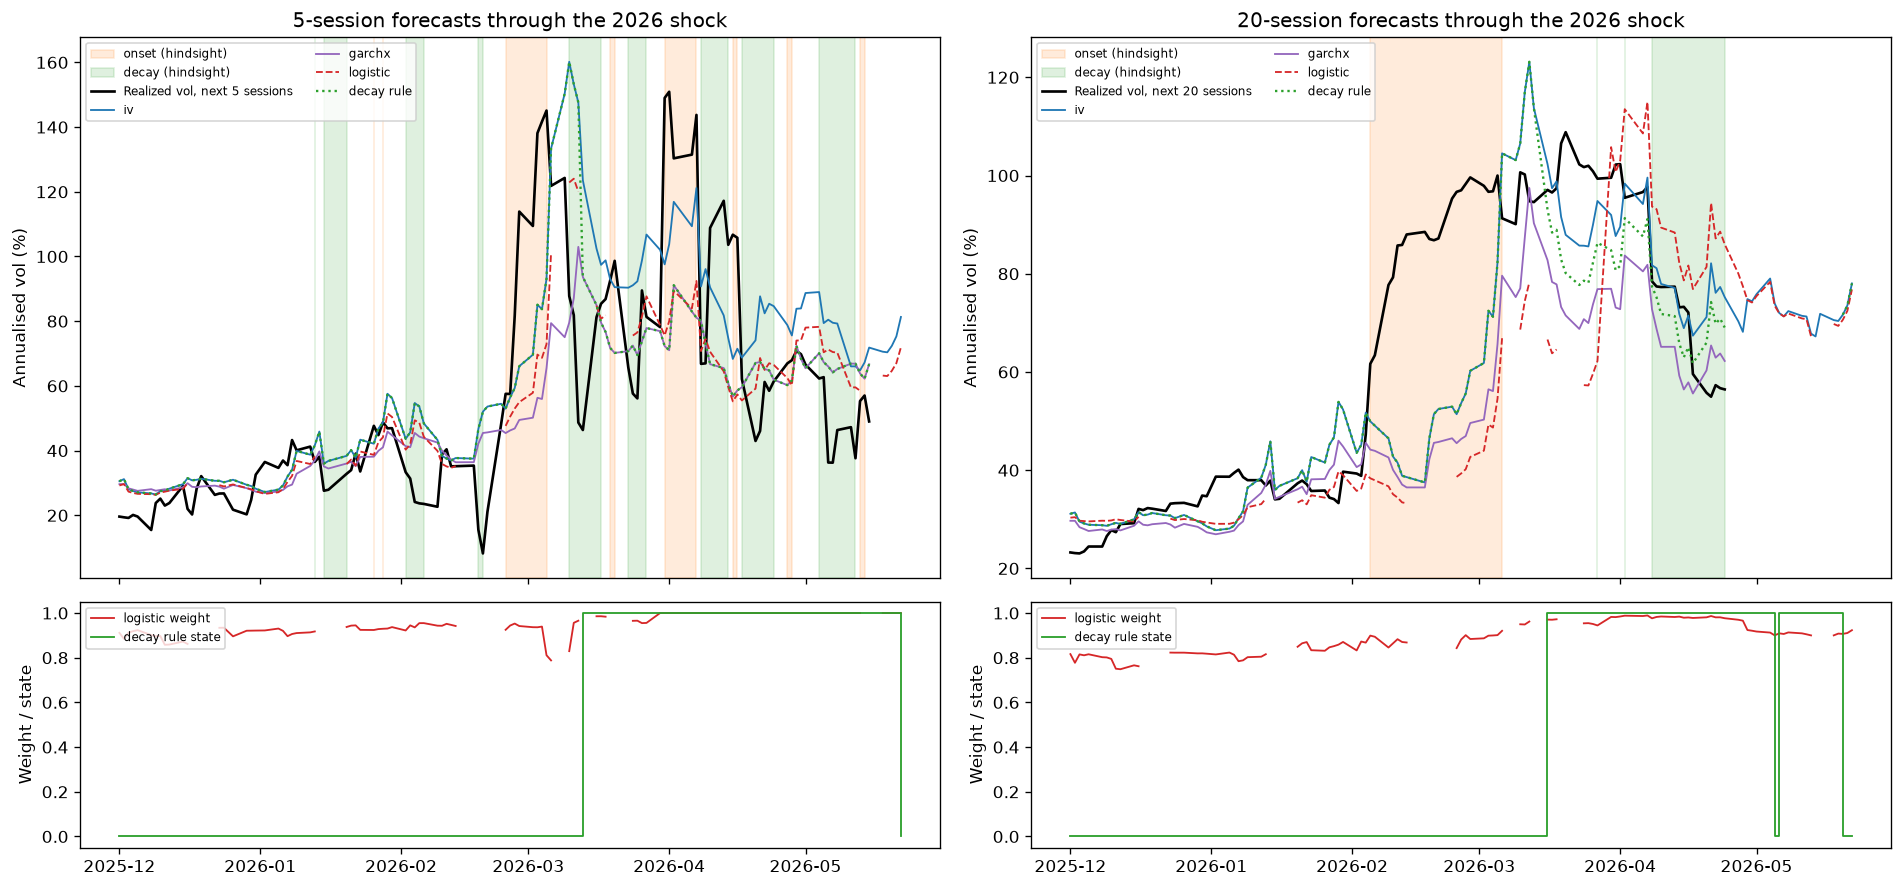

In [12]:
EPISODE_START = "2025-12-01"
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5), sharex="col", gridspec_kw={"height_ratios": [2.2, 1]})
for col, h in enumerate(RESULTS):
    f = RESULTS[h].forecasts.loc[EPISODE_START:]
    labels = LABELS[h].reindex(f.index)
    phase = phase_of(labels)
    best_blend = TIMING_CAPTURE.loc[h].loc[BLENDS, "QLIKE, all"].idxmin()
    ax = axes[0, col]
    for name, color in (("onset", "tab:orange"), ("decay", "tab:green")):
        mask = phase.eq(name).to_numpy()
        ax.fill_between(f.index, 0, 1, where=mask, color=color, alpha=0.15,
                        transform=ax.get_xaxis_transform(), label=f"{name} (hindsight)")
    ax.plot(f.index, 100 * np.sqrt(TARGETS[h].reindex(f.index)), color="black", lw=1.6,
            label=f"Realized vol, next {h} sessions")
    for name, color, style in (("iv", "tab:blue", "-"), ("garchx", "tab:purple", "-"),
                               (best_blend, "tab:red", "--")):
        ax.plot(f.index, 100 * f[name], color=color, ls=style, lw=1.1, label=name)
    ax.plot(f.index, 100 * np.sqrt(DECAY_RULE[h].reindex(f.index)), color="tab:green", ls=":", lw=1.4,
            label="decay rule")
    ax.set(title=f"{h}-session forecasts through the 2026 shock", ylabel="Annualised vol (%)")
    ax.legend(fontsize=7, ncol=2, loc="upper left")
    ax = axes[1, col]
    weights = RESULTS[h].weights.reindex(f.index)
    if best_blend in weights.columns:
        ax.plot(f.index, weights[best_blend], color="tab:red", lw=1.1, label=f"{best_blend} weight")
    ax.step(f.index, DECAY_STATE[h].reindex(f.index), where="post", color="tab:green", lw=1.1,
            label="decay rule state")
    ax.set(ylabel="Weight / state", ylim=(-0.05, 1.05))
    ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
fig.savefig(CONFIG["figures"] / "CL_episode_2026.png", dpi=140)
display(fig)
plt.close(fig)

Over one week, implied vol jumps with the first spike in early March and peaks with it, while the model-based forecasts rise later and stay low through the April re-spike. The fading state switches on in mid-March and stays on into May, so the April spike happens while it is active, which is exactly where the rule loses.

Over one month, every forecast reaches the 100% level about a month after the realized line does. That gap is partly built in: the realized line is dated at the start of its 20-day window, so it shows the spike early. Even so, implied vol leads the models on the way up and on the way down. The logistic weight barely moves, sitting near 0.9 before the shock and near 1.0 during it.

### 8.6 Does the fading phase pay an option seller?

If implied vol stays too high while a shock fades, selling volatility in that phase should pay better than selling at random. The profit of a short variance position over the next `h` days is approximated as `(IV^2 - RV^2) / (2 * IV)` in vol points, positive when the seller gains. The table compares all test dates, dates with the fading state on and off, and the true fading phase known with hindsight. Forecast windows overlap, so the last columns keep only every `h`-th date.

In [13]:
short_rows = []
for h in RESULTS:
    f = RESULTS[h].forecasts.loc[test_start:]
    y = TARGETS[h].reindex(f.index)
    iv_vol = f["iv"]
    pnl = (100 * (iv_vol ** 2 - y) / (2 * iv_vol)).dropna()
    state = DECAY_STATE[h].reindex(pnl.index)
    label = LABELS[h].reindex(pnl.index)["eval_decay"].fillna(0).astype(bool)
    groups = {"all test origins": pnl.index, "decay rule on": pnl.index[state.eq(1)],
              "decay rule off": pnl.index[state.eq(0)], "hindsight decay label": pnl.index[label]}
    for name, dates in groups.items():
        part = pnl.loc[dates]
        spaced = part.iloc[::h]
        short_rows.append({"h": h, "origins": name, "count": len(part),
                           "mean P&L (vol pts)": part.mean(), "median": part.median(),
                           "share positive (%)": 100 * part.gt(0).mean() if len(part) else np.nan,
                           "worst": part.min() if len(part) else np.nan,
                           "non-overlapping count": len(spaced), "non-overlapping mean": spaced.mean()})
SHORT_AFTER_DECAY = pd.DataFrame(short_rows).set_index(["h", "origins"])
SHORT_AFTER_DECAY.to_csv(CONFIG["output"] / "CL_short_vol_by_state.csv")
display(SHORT_AFTER_DECAY.round(2))

count  mean P&L (vol pts)  median  \
h  origins                                                    
5  all test origins         224                3.84    6.39   
   decay rule on             60                6.28   11.12   
   decay rule off           164                2.95    4.51   
   hindsight decay label     49               17.74   18.49   
20 all test origins         209               -2.01    3.36   
   decay rule on             44                0.92    3.07   
   decay rule off           165               -2.79    3.39   
   hindsight decay label     32                5.66    4.31   

                          share positive (%)  worst  non-overlapping count  \
h  origins                                                                   
5  all test origins                    72.32 -78.08                     45   
   decay rule on                       78.33 -65.00                     12   
   decay rule off                      70.12 -78.08                     33   
   hindsight decay label               93.88 -43.09                     10   
20 all test origins                    68.90 -85.70                     11   
   decay rule on                       65.91 -23.39                      3   
   decay rule off                      69.70 -85.70                      9   
   hindsight decay label               84.38  -4.65                      2   

                          non-overlapping mean  
h  origins                                      
5  all test origins                       4.35  
   decay rule on                          8.36  
   decay rule off                         2.75  
   hindsight decay label                 16.23  
20 all test origins                      -4.78  
   decay rule on                          4.63  
   decay rule off                         0.87  
   hindsight decay label                  6.48

Selling volatility for a week earned +3.8 vol points on an average test date, and was profitable 72% of the time. With the fading state on it earned +6.3 points (+8.4 on 12 non-overlapping weeks), against +3.0 with it off. A perfect fading signal would have earned +17.7. Over one month the state earned +0.9 points against -2.8 without it, but on only 3 independent months.

The risk did not go away. The worst week inside the fading state still lost 65 points, because the April re-spike happened while it was on. Selling in the fading phase looks about twice as profitable as selling at random, but the evidence is 12 weeks from a single episode. It is an idea to test on new data, not a result.

## 9 · Does the result depend on settings, and does it carry over to natural gas?

The hard switch has two settings: how strong a signal must be to switch, and how many days it waits before switching back. The heat map shows how much each combination improves onset forecasts over plain HAR, with implied vol's own improvement printed for comparison. It was drawn after the test, and it is not used to choose the reported model.

To see whether the method carries over, everything learned on WTI before the test is frozen and applied unchanged to natural gas over the same dates. Natural gas data feed the signals but are never used to fit or choose anything.

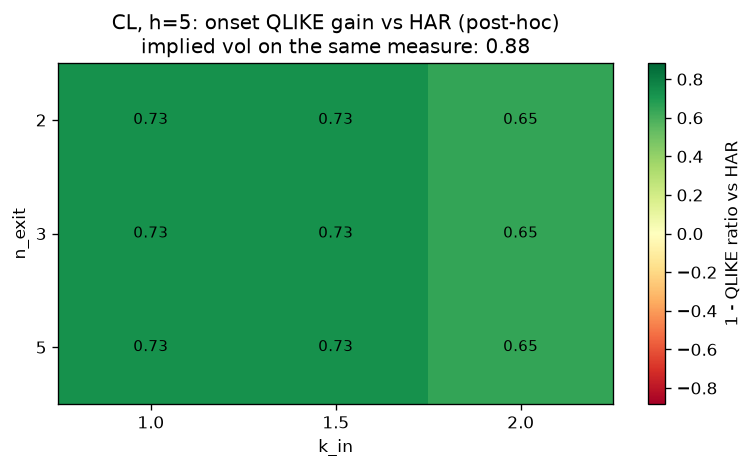

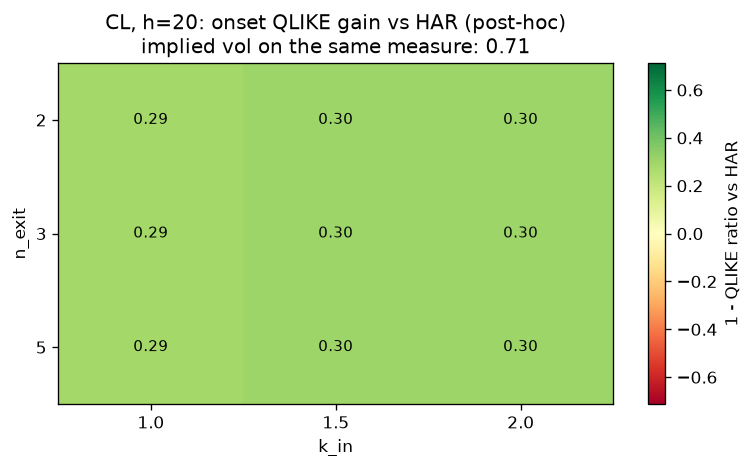

Data quality: 1603 rows retained; 1298 valid; 10 rows in suspicious runs (flagged, not automatically removed).
issue
exact_zero_return                   5
identical_run                       5
invalid_settlement                 40
missing_or_invalid_iv             364
missing_return                    305
non_trading_day                   272
timestamp_alignment_unverified      1


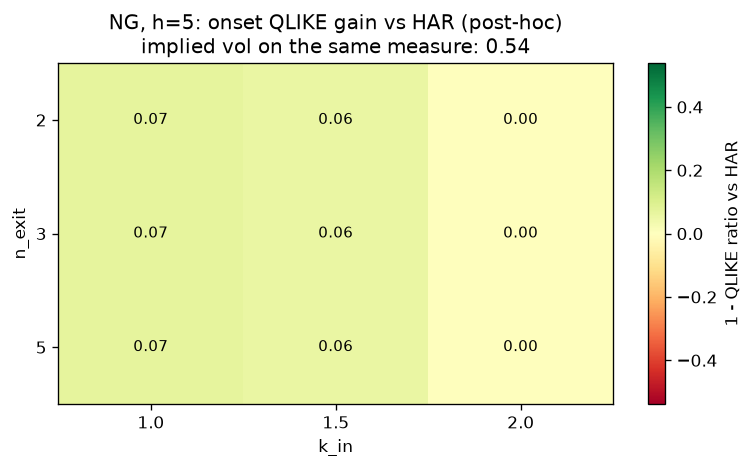

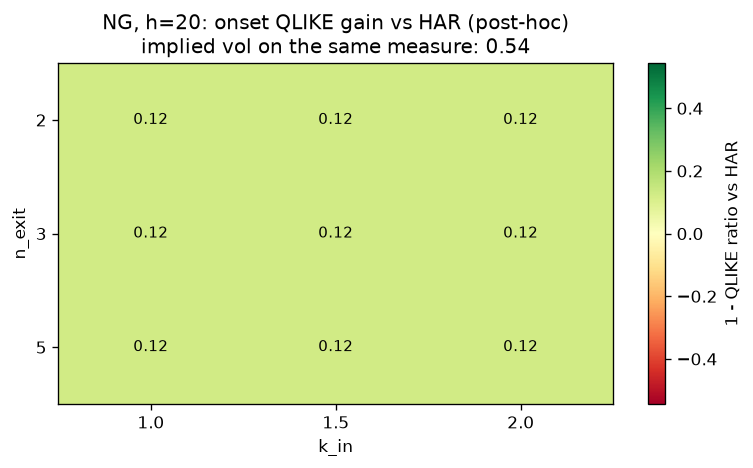

,symbol,status
0,NG,"completed: frozen pre-test WTI parameters, no ..."
1,SPX,not run: no SPX/VIX panel provided


WTI summary
 h     regime  count best_model   QLIKE best_blend  blend_QLIKE  blend_DM_p_vs_constant DM_regime      DM_status  normal99_breaches  normal99_count  median_onset_response  onset_events  onset_censored  onset_unresolved
 5        all    193         iv  0.2589   logistic       0.2913                  0.5969       all             ok                  4             228                    0.5             9               0                 5
 5  eval_calm    129  scaled_iv  0.1853   constant        0.191                     NaN       all benchmark_self                  2             151                      2             9               0                 6
 5 eval_onset     21         iv  0.2941       hard       0.6824                   0.264       all             ok                  2              24                    0.5             9               0                 5
 5 eval_decay     43     garchx  0.3174   constant       0.3439                     NaN       all benchmark_self

In [14]:
def save_heatmap(grid, symbol, h, scores=None):
    table = grid.pivot(index="n_exit", columns="k_in", values="QLIKE gain vs HAR")
    values = table.to_numpy()
    reference = None
    if scores is not None:
        onset = scores.loc[scores.regime.eq("eval_onset")].set_index("model")["QLIKE"]
        if {"iv", "har"} <= set(onset.index):
            reference = 1 - onset["iv"] / onset["har"]
    span = np.nanmax(np.abs(np.append(values, reference if reference is not None else 0.0)))
    fig, ax = plt.subplots(figsize=(6.5, 4))
    image = ax.imshow(values, cmap="RdYlGn", aspect="auto", vmin=-span, vmax=span)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(table.columns)), table.columns)
    ax.set_yticks(range(len(table.index)), table.index)
    title = f"{symbol}, h={h}: onset QLIKE gain vs HAR (post-hoc)"
    if reference is not None:
        title += f"\nimplied vol on the same measure: {reference:.2f}"
    ax.set(xlabel="k_in", ylabel="n_exit", title=title)
    fig.colorbar(image, ax=ax, label="1 - QLIKE ratio vs HAR")
    destination = CONFIG["figures"] / symbol
    destination.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(destination / f"robustness_h{h}.png", dpi=140)
    display(fig)
    plt.close(fig)

for h, result in RESULTS.items():
    grid = robustness_grid(result, TARGETS[h], LABELS[h], h, CONFIG)
    grid.to_csv(CONFIG["output"] / f"CL_robustness_h{h}.csv", index=False)
    save_heatmap(grid, "CL", h, EVALUATIONS[h]["scores"])

TRANSFER_STATUS = []
TRANSFER = {}
for symbol in CONFIG["transfer_symbols"]:
    required = [CONFIG["data_root"] / "Futures" / "Price" / f"{symbol}.parquet",
                CONFIG["data_root"] / "Options" / f"{symbol}_summary.parquet"]
    if not all(path.exists() for path in required):
        TRANSFER_STATUS.append({"symbol": symbol, "status": "not run: required futures/option summary missing"})
        continue
    audited, report = load_existing_panel(CONFIG["data_root"], PROJECT, symbol, CONFIG)
    audited.to_csv(CONFIG["output"] / f"{symbol}_audited_panel.csv")
    report.to_csv(CONFIG["output"] / f"{symbol}_data_quality.csv", index=False)
    destination = audited.loc[audited.forecast_session.eq(True)].copy()
    destination.loc[~destination.quality_valid, "ret"] = np.nan
    evaluations, risks = {}, {}
    for h in CONFIG["horizons"]:
        result = fit_blends(destination, h, CONFIG, frozen=RESULTS[h].states)
        labels = evaluation_labels(destination.ret, h, CONFIG)
        target = forward_variance(destination.ret, h)
        forecasts = result.forecasts.loc[CONFIG["test_start"]:]
        evaluations[h] = evaluate_forecasts(target.reindex(forecasts.index), forecasts,
                                           labels.reindex(forecasts.index), h,
                                           seed=CONFIG["seed"], mcs_reps=CONFIG["mcs_reps"])
        prior = RISKS[h]["nu_path"].loc[
            RISKS[h]["nu_path"].index < pd.Timestamp(CONFIG["test_start"]), "nu"
        ].dropna()
        if prior.empty:
            raise ValueError("No pre-test WTI Student-t estimate available for frozen transfer.")
        risks[h] = var_backtest(destination.ret, result.forecasts, labels, h, CONFIG,
                               hard_mode=result.weights.hard, frozen_nu=float(prior.iloc[-1]))
        for prefix, tables in (("", evaluations[h]), ("risk_", risks[h])):
            for name, table in tables.items():
                table.to_csv(CONFIG["output"] / f"{symbol}_{prefix}{name}_h{h}.csv")
        result.forecasts.to_csv(CONFIG["output"] / f"{symbol}_forecasts_h{h}.csv")
        result.weights.to_csv(CONFIG["output"] / f"{symbol}_weights_h{h}.csv")
        result.coefficients.to_csv(CONFIG["output"] / f"{symbol}_coefficients_h{h}.csv")
        result.diagnostics.to_csv(CONFIG["output"] / f"{symbol}_fit_diagnostics_h{h}.csv", index=False)
        grid = robustness_grid(result, target, labels, h, CONFIG)
        grid.to_csv(CONFIG["output"] / f"{symbol}_robustness_h{h}.csv", index=False)
        save_heatmap(grid, symbol, h, evaluations[h]["scores"])
        plot_evaluation(target.reindex(forecasts.index), forecasts, labels.reindex(forecasts.index),
                        result.weights.reindex(forecasts.index),
                        result.coefficients.loc[CONFIG["test_start"]:], h,
                        CONFIG["figures"] / symbol)
    TRANSFER[symbol] = {"evaluations": evaluations, "risks": risks}
    TRANSFER_STATUS.append({"symbol": symbol, "status": "completed: frozen pre-test WTI parameters, no NG fitting"})
if CONFIG["spx_panel"] is None:
    TRANSFER_STATUS.append({"symbol": "SPX", "status": "not run: no SPX/VIX panel provided"})
else:
    raise NotImplementedError("SPX input requires verified timestamp/unit/schema mapping before transfer.")
display(pd.DataFrame(TRANSFER_STATUS))
pd.DataFrame(TRANSFER_STATUS).to_csv(CONFIG["output"] / "transfer_status.csv", index=False)
print("WTI summary")
SUMMARY = print_summary(EVALUATIONS, RISKS)
SUMMARY.to_csv(CONFIG["output"] / "CL_summary.csv", index=False)
for symbol, results in TRANSFER.items():
    print(symbol, "frozen-transfer summary")
    print_summary(results["evaluations"], results["risks"]).to_csv(
        CONFIG["output"] / f"{symbol}_summary.csv", index=False)

Every setting improves onset forecasts over plain HAR, by 0.65 to 0.73 for one week and 0.29 to 0.30 for one month. Implied vol improves them by 0.88 and 0.71. No setting comes close to implied vol at an onset, and the waiting period makes no difference at all, so the conclusion does not hinge on these choices. The natural-gas results are saved as `NG_*` files in the results folder.

## 10 · Conclusions

**What holds.** Over the next week, each phase of a shock has its own best forecaster. Implied vol wins at the onset, often by a factor of two or more, because the option market reacts first. GARCH-X wins while the shock fades, because implied vol stays high after the peak. In calm markets a rescaled implied vol does slightly better. Over a month, implied vol wins in every phase that matters.

No real-time blend turns this into a better forecast. The best blend scores 0.291 against 0.259 for implied vol over one week, and the hard switch is significantly worse at both horizons. Risk limits also rose late: in the 2026 shock the first one moved 15 trading days after the onset, and it came from implied vol itself.

**Why the blends fail.** The prize is small and short-lived: perfect timing would cut one-week forecast loss by about 12%, and over a month there is nothing to gain. The signals carry real information, but they fire on a quarter to more than half of ordinary days, and the blends barely shift their weights when they do. And a switch has to know when to switch back. The simple fading rule helped while the shock faded, then stayed on through the April re-spike and gave back more than it gained.

**What is suggestive.** Selling volatility while the fading state was on earned roughly twice the usual profit, +6.3 against +3.0 vol points a week. Option-market signals moved weeks before the 2026 shock. Both rest on a single episode and need new data before anyone should rely on them.

**A practical rule.** Use implied vol as the core forecast at both horizons. Lean toward GARCH-X only after a spike, only for short horizons, and hand back to implied vol as soon as implied vol starts rising again. Do not switch away from implied vol on signals built from past returns, because they arrive after the move.

**Limitations.** One stress episode supplies almost every onset and fading date. The one-week implied vol is an approximation on three dates in four. The test period had been studied before, so the results are exploratory. The reused HAR-RV-IV and GARCH-X forecasts were built on a slightly different implied-vol series.

**Next steps.** A locked holdout after May 2026; true one-week implied vol from weekly options; option-market onset signals tested with the scorecard of section 8.3; a fading rule with an exit when implied vol rises, tested on new data and on natural gas; and the fading-phase option sale tested with real option prices.